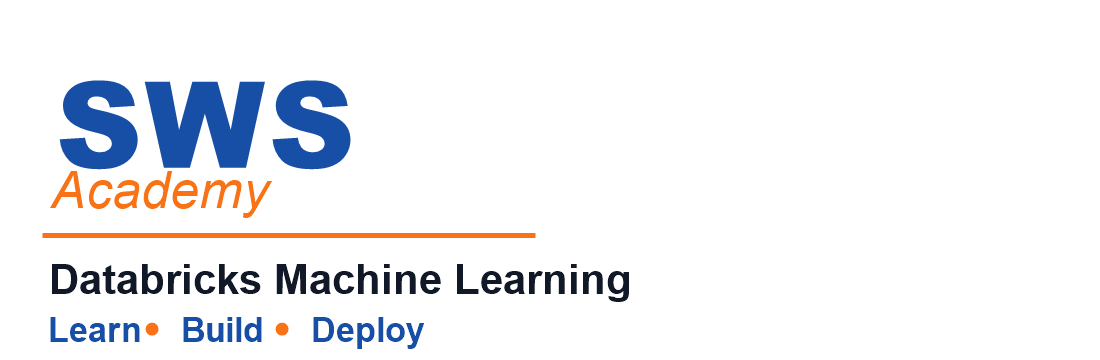

# Unsupervised Learning
In this demo, we will explore **unsupervised learning**, a method where the model finds patterns in **unlabeled data** without predefined categories. We will use **text embeddings** to convert text into numerical representations and apply **K-Means clustering** to group similar text documents.

To improve clustering efficiency, we will **reduce the dimensionality** of embeddings using **Principal Component Analysis (PCA)**. We will also use evaluation techniques like the **Elbow Method** and [**Silhouette Score**](https://en.wikipedia.org/wiki/Silhouette_(clustering) to determine the best number of clusters and assess clustering quality.

**Learning Objectives**

By the end of this demo, you will be able to:

- **Generate text embeddings** using the embeddings model  [General Text Embeddings (GTE)](https://huggingface.co/thenlper/gte-large) to represent text numerically.  
- **Apply dimensionality reduction** (PCA) to optimize clustering performance.  
- **Train an unsupervised K-Means model** to discover patterns in text data.  
- **Determine the optimal number of clusters** using the **Elbow Method**.  
- **Evaluate clustering quality** using **Silhouette Score**.  
- **Visualize clustering results** for better interpretability.

In [ ]:
%pip install --upgrade threadpoolctl scikit-learn
%pip install kneed
%restart_python

## REQUIRED - SELECT A COMPUTE ENVIRONMENT

<div style="border-left: 4px solid #F44336; background: #FFEBEE; padding: 16px 20px; border-radius: 4px; margin: 16px 0;">
<div style="display: flex; align-items: flex-start; gap: 12px;">
<div>
<strong style="color: #C62828; font-size: 1.1em;">Select Compute</strong>
<p style="margin: 8px 0 0 0; color: #333;">Before starting this notebook, select the required compute environment listed below.</p>
<ul style="margin: 12px 0 0 16px; color: #333;">
<li><strong>Serverless Compute, Version 5</strong> — <a href="https://docs.databricks.com/aws/en/compute/serverless/dependencies#-select-an-environment-version" style="color: #1976D2; text-decoration: underline;">How to select an environment version</a></li>
</ul>
<p style="margin: 8px 0 0 0; color: #333;"><strong>NOTE:</strong> This notebook was <strong>developed and tested using Serverless V5</strong>. Other compute options may work but are not guaranteed to behave the same or support all features demonstrated.</p>
</div>
</div>
</div>

<div style="width: 100%; font-family: sans-serif;"><div style="background: #F9F7F4; border-radius: 10px; padding: 24px 28px; box-shadow: 0 2px 8px rgba(27,49,57,0.06); border-top: 6px solid #FF5F46;">  <img src="../Includes/images/genie-code.png" style="height: 64px; margin-bottom: 10px;">  <div style="font-size: 15pt; color: #0B2026; line-height: 1.7; margin-bottom: 16px;">    Want to know more about unsupervised learning and clustering in Databricks? Ask Genie Code. Click on the genie icon <img src="../Includes/images/genie-icon.png" style="height: 32px; vertical-align: middle;"> and begin querying. For example, click the <strong>Copy</strong> button below and paste into <strong>Genie Code</strong>.  </div>  <div style="display: flex; align-items: center; gap: 10px; background: #fff; border: 1px solid #ddd; border-radius: 6px; padding: 10px 14px; font-size: 14pt; font-family: monospace; color: #0B2026;">    <span id="genie-query-1-1b" style="flex: 1;">What is unsupervised learning? How do clustering algorithms like K-Means work in Databricks, and how can I evaluate cluster quality without labeled data?</span>    <button onclick="      var text = document.getElementById('genie-query-1-1b').innerText;      var ta = document.createElement('textarea');      ta.value = text;      ta.style.position = 'fixed';      ta.style.opacity = '0';      document.body.appendChild(ta);      ta.select();      document.execCommand('copy');      document.body.removeChild(ta);      this.innerText = 'Copied!';      var btn = this;      setTimeout(function(){ btn.innerText = 'Copy'; }, 2000);    " style="background: #FF5F46; color: white; border: none; border-radius: 4px; padding: 4px 12px; font-size: 13pt; cursor: pointer; white-space: nowrap;">Copy</button>  </div></div></div>

### Classroom Setup

Run the following cell to configure your working environment for this course.

This setup will:
- Initialize the `SA` object (SWSAcademy helper)
- Configure your **default catalog** and **schema**
- Provision any supporting configuration needed for this demo

**NOTE:** The `SA` object is only available in SWSAcademy courses.

In [ ]:
%run ../Includes/Classroom-Setup-1.1bUS

**Other Conventions:**

Throughout this demo, we'll refer to the object `SA`. This object, provided by SWSAcademy, contains variables such as your username, catalog name, schema name, working directory, and dataset locations. Run the code block below to view these details:

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")
print(f"Dataset Location:  {SA.paths.datasets}")

## Load Data & Generate Embeddings

Before we can apply **unsupervised learning**, we need to load and process our dataset. In this step, we will:

- Load the **AG News dataset** from a **Databricks feature table**.
- Extract the **text column** for processing.
- Prepare the data for **embedding generation**.

### Load the Dataset
We use the **AG News dataset**, which contains news articles, to perform text clustering. The dataset is stored in a **Databricks feature table**, and we will load it as a **Spark DataFrame**.

In [ ]:
import os
from pyspark.sql.functions import col

# Load AG News dataset as a Spark DataFrame (Feature Table)
table_name = f"{SA.catalog_name}.{SA.schema_name}.ag_news_features"
news_df = spark.read.table(table_name)

# Select only the 'text' column (avoiding unnecessary columns)
news_texts_df = news_df.select(col("text"))

# Display the Spark DataFrame
display(news_texts_df)

### Generate Text Vectors for Clustering

Now that we have loaded our text dataset, the next step is to convert the text data into **numerical representations** that clustering algorithms can understand.

For the scheduled classroom job, this notebook uses a local `HashingVectorizer`. This keeps the demo deterministic, inexpensive, and independent of Model Serving rate limits.

For a live instructor demo, you can set `USE_FOUNDATION_MODEL_EMBEDDINGS = True` in the next code cell to use the `databricks-gte-large-en` foundation model endpoint instead. That optional path is useful to explain embeddings, but it may consume Model Serving quota and can be rate limited on trial/shared workspaces.

**Steps:**
- Step 1: Take a small deterministic sample for the classroom demo
- Step 2: Convert text into numeric vectors
- Step 3: Convert the vector list to a Spark DataFrame

In [ ]:
from pyspark.sql.functions import col
from sklearn.feature_extraction.text import HashingVectorizer

# Keep the classroom/job run small and deterministic.
DEMO_SAMPLE_SIZE = 80
USE_FOUNDATION_MODEL_EMBEDDINGS = False

# Convert DataFrame to list on the driver
news_texts_list = (
    news_texts_df
    .select("text")
    .limit(DEMO_SAMPLE_SIZE)
    .toPandas()["text"]
    .tolist()
)

if USE_FOUNDATION_MODEL_EMBEDDINGS:
    # Optional instructor path: this uses Databricks foundation model serving.
    # It can be rate limited on trial/shared workspaces, so jobs use the local
    # path below by default.
    import time
    from openai import RateLimitError
    from databricks.sdk import WorkspaceClient

    workspace_client = WorkspaceClient()
    openai_client = workspace_client.serving_endpoints.get_open_ai_client()

    def get_embeddings_batch(text_batch, max_retries=5):
        for attempt in range(max_retries):
            try:
                response = openai_client.embeddings.create(
                    model="databricks-gte-large-en",
                    input=text_batch
                )
                return [res.embedding for res in response.data]
            except RateLimitError:
                if attempt == max_retries - 1:
                    raise
                wait_seconds = min(60, 5 * (attempt + 1))
                print(f"Embedding endpoint rate limited. Waiting {wait_seconds} seconds before retry {attempt + 2}/{max_retries}.")
                time.sleep(wait_seconds)

    embedding_batch_size = 16
    embeddings_list = []
    for i in range(0, len(news_texts_list), embedding_batch_size):
        batch = news_texts_list[i:i + embedding_batch_size]
        print(f"Embedding records {i + 1}-{i + len(batch)} of {len(news_texts_list)}")
        embeddings_list.extend(get_embeddings_batch(batch))
else:
    # Default job path: create deterministic local text vectors. This keeps the
    # unsupervised learning demo runnable without consuming Model Serving quota.
    vectorizer = HashingVectorizer(
        n_features=1024,
        alternate_sign=False,
        norm="l2"
    )
    embeddings_list = vectorizer.transform(news_texts_list).toarray().tolist()

# Create DataFrame with embeddings
embeddings_df = spark.createDataFrame(zip(news_texts_list, embeddings_list), ["text", "embedding"])

## Standardization and Dimensionality Reduction

Now that we have generated **text embeddings**, we need to prepare them for clustering by applying **standardization** and **dimensionality reduction**.

**Why Do We Need This Step?**
- **Standardization** ensures that all features have a similar scale, preventing some features from dominating others.
- **Dimensionality Reduction** using [**Principal Component Analysis (PCA)**](https://en.wikipedia.org/wiki/Principal_component_analysis) helps reduce the number of features while retaining important information. This makes clustering more efficient and easier to visualize. In particular, we will be converting our embedding from 1024 dimensions down to 2 dimensions.


### Vector Normalization Implementation
The L2 normalization ensures all vectors have unit length, making cosine similarity equivalent to dot product and focusing the clustering algorithm on the directional relationships between embeddings.

In [ ]:
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
import numpy as np

# Convert Spark DataFrame to NumPy array (Extract embeddings)
embeddings_np = np.array([row["embedding"] for row in embeddings_df.select("embedding").collect()])

# Step 1: Normalize embeddings to unit vectors
embeddings_normalized = normalize(embeddings_np, norm='l2')

# Step 2: Dimensionality Reduction using PCA
pca = PCA(n_components=2)  # Reduce to 2D for visualization
embeddings_pca = pca.fit_transform(embeddings_normalized)

# Convert back to Spark DataFrame
pca_df = spark.createDataFrame(
    [(int(i), float(pc1), float(pc2)) for i, (pc1, pc2) in enumerate(embeddings_pca)],
    ["unique_id", "PC1", "PC2"]
)

# Display the transformed embeddings
display(pca_df)

# Optional: Check normalization effect
print(f"Original embeddings shape: {embeddings_np.shape}")
print(f"Normalized embeddings shape: {embeddings_normalized.shape}")
print(f"Sample vector magnitude before normalization: {np.linalg.norm(embeddings_np[0]):.4f}")
print(f"Sample vector magnitude after normalization: {np.linalg.norm(embeddings_normalized[0]):.4f}")


### Clustering with Normalized Embeddings
Now we'll perform clustering using the normalized embeddings. The clustering algorithm will focus on the semantic direction of the text rather than the embedding magnitude.

In [ ]:
from sklearn.cluster import KMeans
import numpy as np

# Perform K-means clustering on normalized embeddings
n_clusters = 4  # Based on AG News dataset having 4 categories

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(embeddings_normalized)

print(f"Number of clusters: {n_clusters}")
print("Cluster distribution:")

unique, counts = np.unique(cluster_labels, return_counts=True)

for cluster_id, count in zip(unique, counts):
    print(f"  Cluster {cluster_id}: {count} articles")


### Cluster Analysis and AG News Dataset Exploration
The AG News dataset contains articles from four main categories: World (0), Sports (1), Business (2), and Sci/Tech (3). We'll examine our learned clusters to see if they align with these semantic categories.


### Creating Cluster Analysis DataFrame
We'll combine our clustering results with the original news text to analyze what topics each cluster has learned to identify.

In [ ]:
# Create DataFrame with cluster assignments
unique_ids = news_df.select("unique_id").toPandas()["unique_id"].tolist()
cluster_data = [(int(uid), int(cid)) for uid, cid in zip(unique_ids, cluster_labels)]

clusters_spark_df = spark.createDataFrame(cluster_data, ["unique_id", "Cluster"])

print("Cluster assignments created successfully!")
display(clusters_spark_df.groupBy("Cluster").count().orderBy("Cluster"))


### Examining Individual Clusters
Let's examine each cluster to identify the topics our algorithm has learned. Based on the AG News documentation, we expect to find clusters roughly corresponding to:

World news (international affairs, politics)
Sports (athletics, games, competitions)
Business (markets, finance, economics)
Science/Technology (tech developments, scientific discoveries)

In [ ]:
# Examine Cluster 0 - Change the cluster number to investigate each cluster
display(
    clusters_spark_df
    .join(news_df, "unique_id")
    .filter(clusters_spark_df.Cluster == 0)
    .select(clusters_spark_df["*"], news_df["text"])
    .limit(10)
)


### Interactive Cluster Exploration
Note: Try changing the cluster number in the cell above (0, 1, 2, or 3) to explore different learned topics. Look for patterns in the text content that suggest semantic categories.

In [ ]:
# Quick cluster content analysis
for cluster_id in range(n_clusters):
    print(f"\n=== CLUSTER {cluster_id} SAMPLE ===")
    sample_texts = (clusters_spark_df
                   .join(news_df, "unique_id")
                   .filter(clusters_spark_df.Cluster == cluster_id)
                   .select("text")
                   .limit(3)
                   .toPandas()['text'].head(3).tolist())
    
    for i, text in enumerate(sample_texts, 1):
        print(f"{i}. {text[:150]}...")

## Determine the Optimal Number of Clusters (Elbow Method)

Before applying [K-Means](https://en.wikipedia.org/wiki/K-means_clustering) clustering, we need to determine the **best number of clusters (K)**.  
We use the [**Elbow Method**](https://en.wikipedia.org/wiki/Knee_of_a_curve), which helps identify the point where adding more clusters **no longer significantly reduces inertia (sum of squared distances to cluster centers).**  

**How Does the Elbow Method Work?**
- We run **K-Means** clustering for different values of K (from 1 to 10).
- We measure **inertia** (how well points fit within their assigned cluster).
- We plot inertia against K and look for the [**elbow point**](https://en.wikipedia.org/wiki/Elbow_method_(clustering) where the decrease in inertia slows down.
- The **optimal K** is found using **KneeLocator**, which detects the elbow point automatically.

**Why not just minimize inertia?**
- Minimizing inertia can lead to _overfitting_ (continuously decreasing while increasing the number of clusters will fit noise rather than meaningful patterns).
- The elbow method provides interpretability and voids arbitrary decision-making by providing a point of diminishing returns.

> We manually set the environment variable `OMP_NUM_THREADS` to 1 to avoid multithreading and parallelism to ensure that each run uses the same computational resources. This prevents the creation of too many threads across processes, preventing inefficient CPU utilization.

In [ ]:
import os
import threadpoolctl
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from kneed import KneeLocator 

# Apply fixes for parallel processing
os.environ["OMP_NUM_THREADS"] = "1"
threadpoolctl.threadpool_limits(limits=1, user_api="blas")

# Perform K-Means clustering and compute inertia
inertia = []
k_values = range(1, 10)  # Try values from 1 to 10

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(embeddings_pca)  # Use PCA-transformed embeddings
    inertia.append(kmeans.inertia_)

# Use KneeLocator to find the elbow point
knee_locator = KneeLocator(k_values, inertia, curve="convex", direction="decreasing")
optimal_k = knee_locator.elbow

# Plot Elbow Method with detected optimal k
plt.figure(figsize=(8,6))
plt.plot(k_values, inertia, marker='o', linestyle='--', label='Inertia')
plt.axvline(x=optimal_k, color='r', linestyle='--', label=f'Optimal K={optimal_k}')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.legend()
plt.show()

print(f"Optimal number of clusters: {optimal_k}")

## Apply Clustering Algorithm

We will now apply **K-Means Clustering** to group similar news articles together based on their embeddings.

**Steps:**
1. **Train the K-Means model** using the **optimal_k**.
2. **Assign cluster labels** to each news article.
3. **Store clustering results** in a Spark DataFrame.

In [ ]:
from pyspark.sql.functions import monotonically_increasing_id
from sklearn.cluster import KMeans
import pandas as pd

# Apply K-Means clustering on the reduced embeddings
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(embeddings_pca)  # Use PCA-transformed embeddings

# Get cluster labels
labels = kmeans.labels_

# Convert labels to a Spark DataFrame
labels_df = pd.DataFrame({"unique_id": range(len(labels)), "Cluster": labels})
labels_spark_df = spark.createDataFrame(labels_df)

# Join PCA-transformed Spark DataFrame with cluster labels
clusters_spark_df = pca_df.join(labels_spark_df, "unique_id")

# Display the resulting clustered DataFrame
display(clusters_spark_df)

## Evaluate Clustering Performance

Once the **K-Means clustering** is applied, we need to assess how well the clusters are formed. A common metric for this evaluation is the **Silhouette Score**.

### Silhouette Score
_The silhouette value measures how well an object fits its assigned cluster compared to other clusters_, ranging from -1 to +1, with higher values indicating better clustering. It provides a metric for evaluating clustering quality, with average scores above 0.5 considered reasonable, though high-dimensional data may yield lower scores due to the curse of dimensionality.

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(embeddings_pca, labels)
print(f"Silhouette Score for K-Means with {optimal_k} clusters: {silhouette_avg}")

## Visualize Clustering Results

we will visualize the clusters to gain insights into how the news articles are grouped based on their embeddings. Here we will be using the method ConvexHull to help visualize. This compute the convex hull in N dimensions (here N = 2). This helps us identify the boundary of a set of clusters.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull

# Convert Spark DataFrame to Pandas
clusters_pd = clusters_spark_df.toPandas()

# Define color palette
num_clusters = clusters_pd["Cluster"].nunique()
colors = sns.color_palette("husl", num_clusters)  # Distinct colors

plt.figure(figsize=(10, 7))

# Scatter plot with better visibility
for cluster, color in zip(range(num_clusters), colors):
    subset = clusters_pd[clusters_pd["Cluster"] == cluster]
    
    plt.scatter(
        subset["PC1"], subset["PC2"],
        label=f"Cluster {cluster}",
        color=color, s=80, alpha=0.6, edgecolors='k'  # Larger points, transparency, black edges
    )

    # Convex Hull for cluster boundary (only if there are enough points)
    if len(subset) > 2:
        hull = ConvexHull(subset[["PC1", "PC2"]])
        for simplex in hull.simplices:
            plt.plot(subset.iloc[simplex]["PC1"], subset.iloc[simplex]["PC2"], color=color, alpha=0.5)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Clustering Visualization of News Articles")
plt.legend()
plt.grid(True)
plt.show()

## Conclusion
In this demo, we explored the process of **training an unsupervised model** using **K-Means clustering** on **text embeddings**. We generated embeddings with **Databricks foundation models**, standardized the data, and applied **dimensionality reduction (PCA)** to optimize clustering. By using the **Elbow Method** and **Silhouette Score**, we determined the optimal number of clusters and evaluated the quality of our model. This approach helps in discovering hidden patterns in text data, making it a powerful technique for **automated categorization and pattern recognition** in **real-world applications**.

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>